# Problem
Infer81apparent kinetic barrier values from five real mass-loss experiments. The unknown is E(alpha), not a mass image; this is a nonspatial kinetic inverse problem. No independent energy truth exists.

In [1]:
from pathlib import Path
import os,sys,time,numpy as np,matplotlib.pyplot as plt
p=Path.cwd()
if not (p/'src').exists():p=p.parent
os.chdir(p);sys.path.insert(0,str(p))
from src.preprocessing import load_data,prepare
from src.solvers import reconstruct,integral_energy
from src.physics_model import centered_log_residual
traces=load_data();data=prepare(traces)
original=np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False)
from src.visualization import thermograms


## Data
All five complete author n-decane records,62112 points, are real thermobalance observations. Temperature, time and mass are measured; rates are estimated from the full records. The original method result supplies a comparison only.

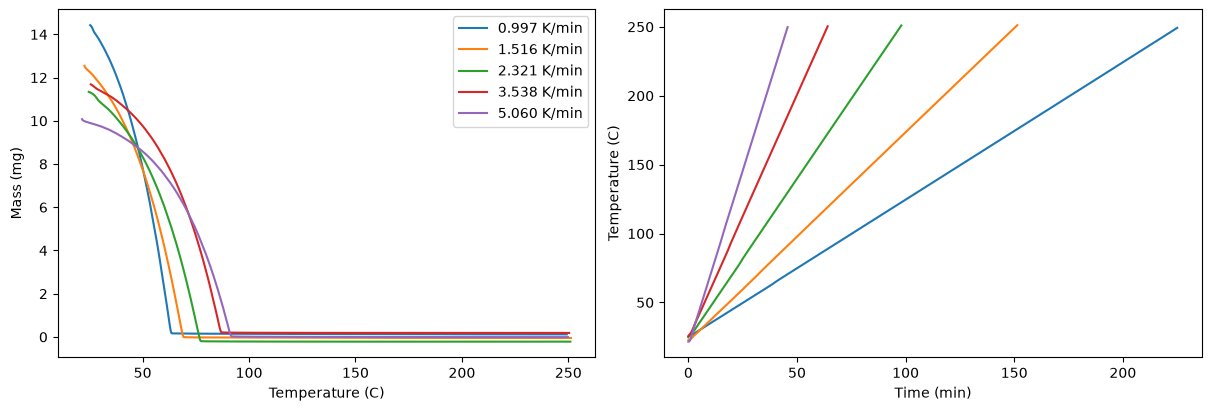

In [2]:
thermograms(traces,data["beta"]);plt.show()

## Physics
The Arrhenius model d(alpha)/dt=A f(alpha) exp(-E(alpha)/(RT)) links mass loss to energy barriers. Alpha=(m0-m)/(m0-mf), R=.0083144626kJ/(mol K), T is K and time is min. Shared conversion dependence cancels between ramps within short conversion intervals. Apparent barriers can include transport effects; no molecular-mechanism claim is made.

## Method
Fit each energy so narrow-interval Arrhenius time integrals agree across all five observed heating histories. Explicit pairwise ratio objective, trapezoid discretization and bounded scalar Brent updates implement the selected author method. Preprocessing follows original monotone conversion, cubic interpolation and four-decimal tables.

$$\dot{\alpha}=A f(\alpha)\exp[-E(\alpha)/(RT)].$$

For ramp i and interval j, J is its trapezoidal Arrhenius time integral; minimize the pairwise-ratio objective below. All symbols use the units stated above.

$$\Omega(E)=\sum_i\sum_{l\ne i}J_i(E)/J_l(E),\qquad \Omega(E)\ge n(n-1),\quad n=5.$$


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\material_mechanics\tasks\thermogravimetric_isoconversional_activation_energy\src\solvers.py:26: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  roots=np.array([fsolve(interp,energy-150)[0],fsolve(interp,energy+150)[0]])
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\material_mechanics\tasks\thermogravimetric_isoconversional_activation_energy\src\solvers.py:26: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  roots=np.array([fsolve(interp,energy-150)[0],fsolve(interp,energy+150)[0]])


Full fresh method/comparison seconds 4.4618478999473155
Energy relative RMS 0.0


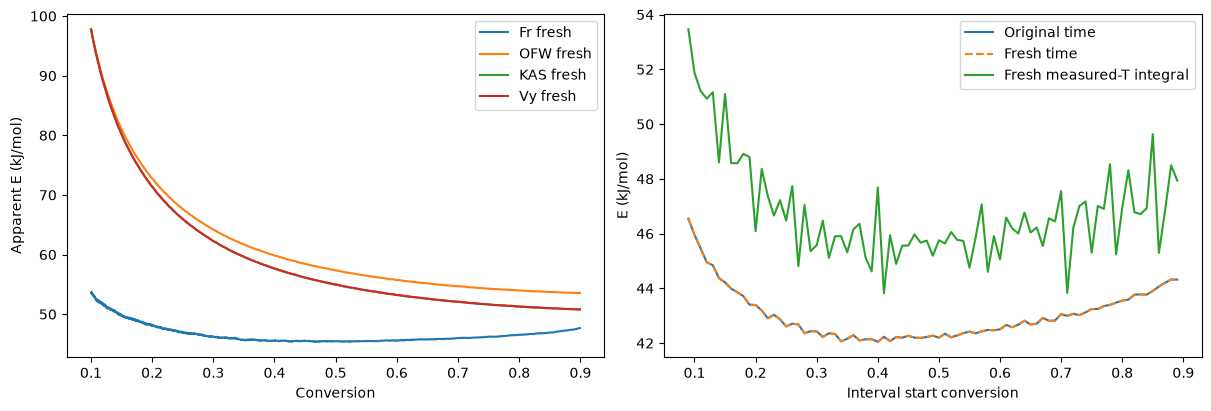

In [3]:
tick=time.perf_counter();fresh=reconstruct(data,comparisons=True);print('Full fresh method/comparison seconds',time.perf_counter()-tick)
print('Energy relative RMS',np.linalg.norm(fresh['reconstruction'][0]-original['aVy'][0])/np.linalg.norm(original['aVy'][0]))
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for name in ['Fr','OFW','KAS','Vy']:
 axs[0].plot(data['alpha'],fresh[name][0],label=name+' fresh')
axs[0].legend();axs[0].set(xlabel='Conversion',ylabel='Apparent E (kJ/mol)')
a=data['advanced_alpha'][:-1];axs[1].plot(a,original['aVy'][0],label='Original time');axs[1].plot(a,fresh['aVy'][0],'--',label='Fresh time');axs[1].plot(a,fresh['aVy_temperature'][0],label='Fresh measured-T integral');axs[1].legend();axs[1].set(xlabel='Interval start conversion',ylabel='E (kJ/mol)');plt.show()

## Results
All five published estimators are freshly computed above. Upstream KAS uses exponent1.92, not classic2. Temperature integration is a distinct history approximation. Agreement with reproduced original does not establish physical truth. Original signed error and temperature-branch variance bugs are retained only as identified diagnostics; they are not valid confidence intervals. fsolve progress warnings are exposed.

Observation log RMS 0.046194985268225464


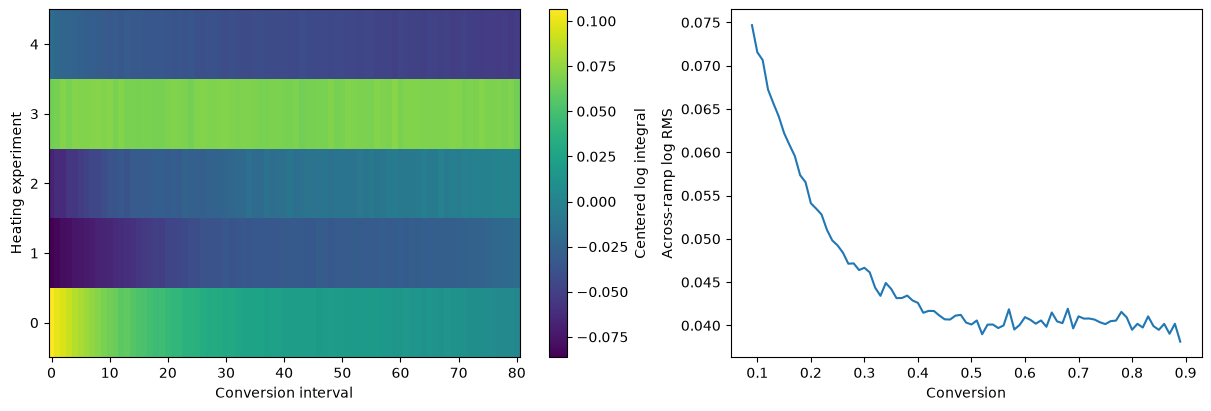

In [4]:
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
res=centered_log_residual(fresh['reconstruction'][0],data);im=axs[0].imshow(res.T,aspect='auto',origin='lower');fig.colorbar(im,ax=axs[0],label='Centered log integral');axs[0].set(xlabel='Conversion interval',ylabel='Heating experiment')
axs[1].plot(a,np.sqrt(np.mean(res**2,axis=1)));axs[1].set(xlabel='Conversion',ylabel='Across-ramp log RMS');print('Observation log RMS',np.sqrt(np.mean(res**2)));plt.show()

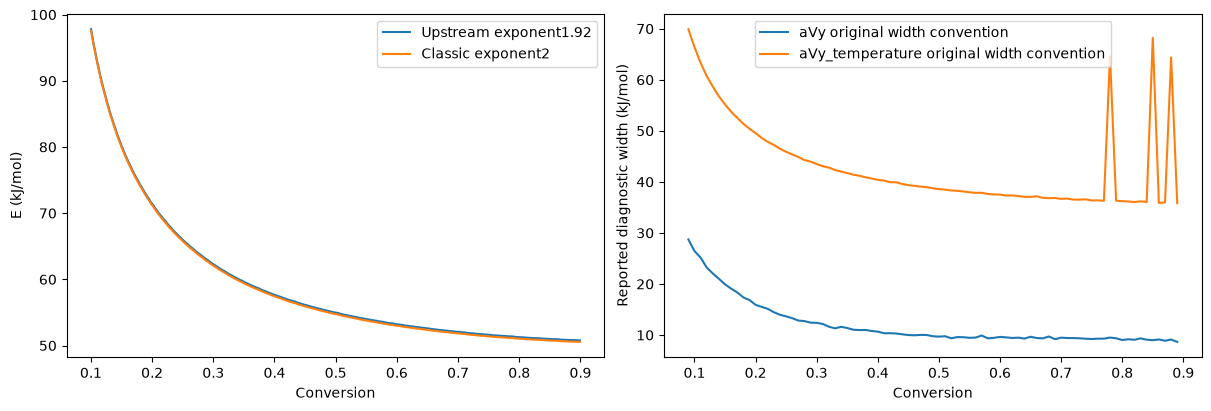

In [5]:
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axs[0].plot(data['alpha'],fresh['KAS'][0],label='Upstream exponent1.92');axs[0].plot(data['alpha'],fresh['KAS_classic'][0],label='Classic exponent2');axs[0].legend();axs[0].set(xlabel='Conversion',ylabel='E (kJ/mol)')
for k in ['aVy','aVy_temperature']:axs[1].plot(a,fresh[k][1],label=k+' original width convention')
axs[1].legend();axs[1].set(xlabel='Conversion',ylabel='Reported diagnostic width (kJ/mol)');plt.show()

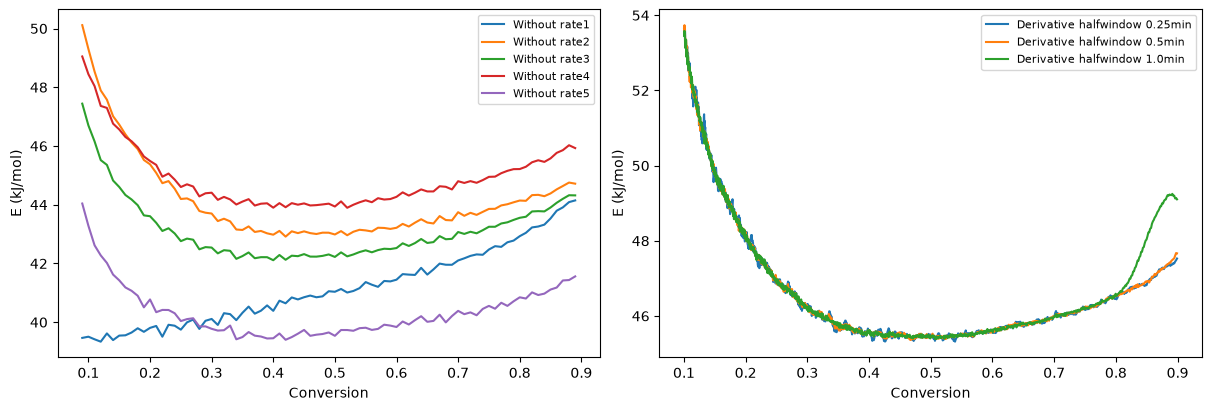

In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i in range(5):
 sub=dict(data);sub['beta']=np.delete(data['beta'],i);sub['initial_temperature']=np.delete(data['initial_temperature'],i)
 for key in ['advanced_time','advanced_temperature']:sub[key]=np.delete(data[key],i,axis=1)
 energy=integral_energy(sub,with_errors=False);axs[0].plot(a,energy,label=f'Without rate{i+1}')
for window in [.25,.5,1.]:
 d=prepare(traces,half_window=window);from src.solvers import linear_energy
 q=linear_energy(d['temperature'],d['rate'],d['beta'],'Fr');axs[1].plot(d['alpha'],q[0],label=f'Derivative halfwindow {window}min')
for ax in axs:ax.legend(fontsize=8);ax.set(xlabel='Conversion',ylabel='E (kJ/mol)')
plt.show()

## Conclusion
Multiple heating histories recover a conversion-dependent apparent barrier. Five original methods, measured-history comparison, residuals, leave-one-rate-out and smoothing studies expose model dependence. Lack of independent energy truth and original uncertainty inconsistencies limit physical accuracy claims. All plotted fresh results were reconstructed from the bound measurements.